In [1]:
import pandas as pd

df = pd.read_csv("housing.csv")

display(df.head())
print("Dataset shape:", df.shape)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Dataset shape: (20640, 10)


Step 1: Load the dataset in Jupyter Notebook

In [2]:
import pandas as pd

df = pd.read_csv("housing.csv")

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB


None

Step 2: Check the target column

In [3]:
print(df.columns.tolist())

['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


Step 3: Check for missing values

In [6]:
print(df.isnull().sum())

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [7]:
# Check missing values before handling them
print("Missing values before:")
print(df.isnull().sum())

# Fill missing values using the median
df["total_bedrooms"] = df["total_bedrooms"].fillna(
    df["total_bedrooms"].median()
)

# Check again
print("\nMissing values after:")
print(df.isnull().sum())

Missing values before:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Missing values after:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


In [8]:
print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)

Dataset shape: (20640, 10)

Data types:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object


In [9]:
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 9)
Target shape: (20640,)


In [10]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 9)
Testing features: (4128, 9)
Training target: (16512,)
Testing target: (4128,)


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = ["ocean_proximity"]

# Process numerical and categorical columns
preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing setup completed!")

Preprocessing setup completed!


In [15]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline

# Define the three models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(
    alpha=1000,
    max_iter=50000,
    tol=0.001
)
}

trained_models = {}
predictions = {}

# Train and predict using each model
for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions[name] = pipeline.predict(X_test)
    trained_models[name] = pipeline

    print(f"{name} trained successfully!")

print("\nAll three models have been trained.")

Linear Regression trained successfully!
Ridge Regression trained successfully!
Lasso Regression trained successfully!

All three models have been trained.


In [13]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import pandas as pd

results = []

for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "RMSE": mean_squared_error(y_test, y_pred) ** 0.5,
        "MAE": mean_absolute_error(y_test, y_pred),
        "R2 Score": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df.round(4))

,Model,RMSE,MAE,R2 Score
0,Linear Regression,70060.5218,50670.7382,0.6254
2,Lasso Regression,70060.6320,50670.8587,0.6254
1,Ridge Regression,70067.3465,50677.1710,0.6254


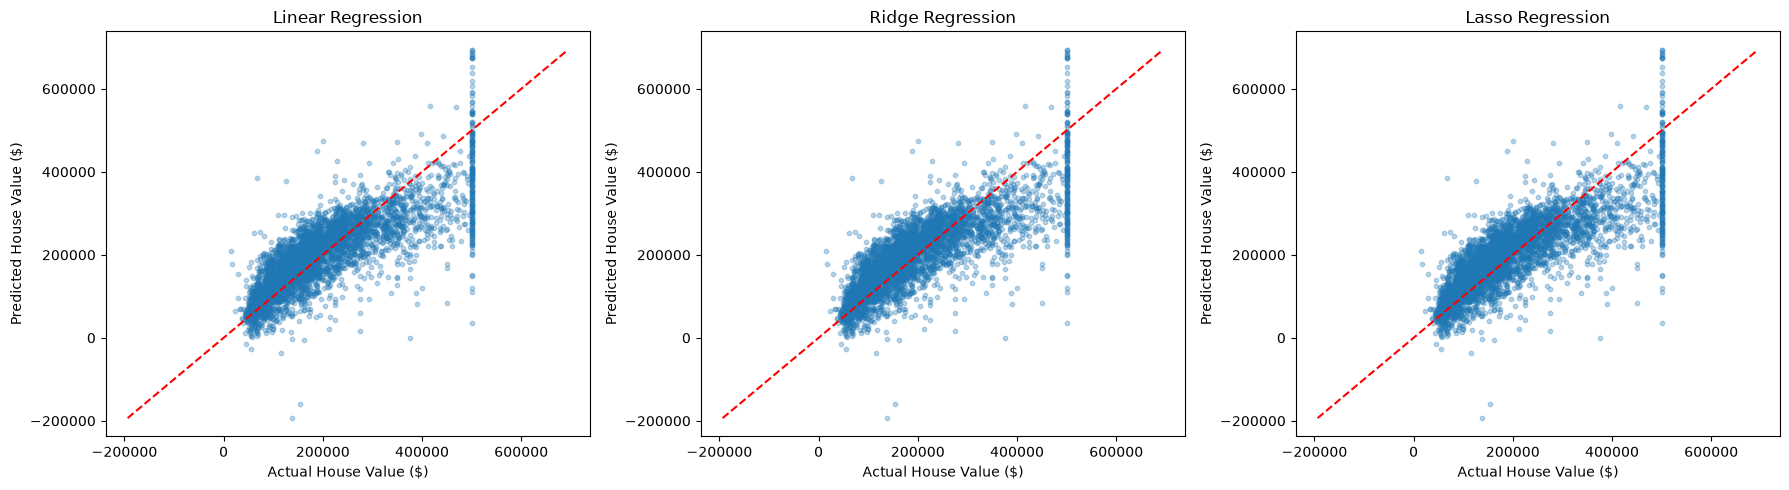

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.3, s=10)

    low = min(y_test.min(), y_pred.min())
    high = max(y_test.max(), y_pred.max())

    ax.plot([low, high], [low, high], "r--")
    ax.set_title(name)
    ax.set_xlabel("Actual House Value ($)")
    ax.set_ylabel("Predicted House Value ($)")

plt.tight_layout()
plt.show()